# **1. Import Libraries and Set Seed**

In [1]:
import pandas as pd
import numpy as np
import os
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# **2. Load Dataset**

In [2]:
!kaggle datasets download -d viroshensewpaul/general-household-survey-data-from-2012-to-2022

!unzip -o general-household-survey-data-from-2012-to-2022.zip -d /content/

Dataset URL: https://www.kaggle.com/datasets/viroshensewpaul/general-household-survey-data-from-2012-to-2022
License(s): apache-2.0
100% 41.7M/41.7M [00:00<00:00, 130MB/s] 

Archive:  general-household-survey-data-from-2012-to-2022.zip
  inflating: /content/ghs-2012-person-v2.1.csv  
  inflating: /content/ghs-2013-person-v1.csv  
  inflating: /content/ghs-2014-person-v1.csv  
  inflating: /content/ghs-2015-person-v1.csv  
  inflating: /content/ghs-2016-person-v1.csv  
  inflating: /content/ghs-2017-person-1.0.csv  
  inflating: /content/ghs-2018-person-v1.csv  
  inflating: /content/ghs-2019-person-v1.csv  
  inflating: /content/ghs-2020-person-v1.csv  
  inflating: /content/ghs-2021-person-v1.csv  
  inflating: /content/ghs-2022-person-v1.csv  


In [3]:
# COMBINE GHS 2012–2022 DATASETS

files = sorted([
    f for f in os.listdir("/content")
    if f.startswith("ghs-") and f.endswith(".csv")
])

dfs = []

for file in files:

    # Extract survey year from filename
    year = int(
        re.search(r"ghs-(\d{4})", file).group(1)
    )

    # Read annual dataset
    temp = pd.read_csv(
        f"/content/{file}",
        encoding="latin1",
        low_memory=False
    )

    # Add survey year
    temp["Survey_Year"] = year

    dfs.append(temp)

# Combine all years
ghs_df = pd.concat(
    dfs,
    ignore_index=True
)

print("Combined dataset shape:")
print(ghs_df.shape)

print("\nObservations by survey year:")
print(
    ghs_df["Survey_Year"]
    .value_counts()
    .sort_index()
)

Combined dataset shape:
(773311, 726)

Observations by survey year:
Survey_Year
2012    91859
2013    93749
2014    92459
2015    74449
2016    72602
2017    72291
2018    71137
2019    68986
2020    34370
2021    35265
2022    66144
Name: count, dtype: int64


# **3. Data Preprocessing**

## **Harmonise Province**

In [4]:
province_map = {
    "1": "Western Cape",
    "2": "Eastern Cape",
    "3": "Northern Cape",
    "4": "Free State",
    "5": "KwaZulu-Natal",
    "6": "North West",
    "7": "Gauteng",
    "8": "Mpumalanga",
    "9": "Limpopo"
}

# Combine province columns
ghs_df["Province"] = (
    ghs_df["Prov"]
    .combine_first(ghs_df["prov"])
)

# Standardise format
ghs_df["Province"] = (
    ghs_df["Province"]
    .astype(str)
    .str.strip()
    .replace(province_map)
    .replace("nan", np.nan)
)

print(
    ghs_df["Province"]
    .value_counts(dropna=False)
)

/tmp/ipykernel_411/1558372840.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ghs_df["Province"] = (


Province
Gauteng          148531
KwaZulu-Natal    137301
Eastern Cape     101839
Limpopo           93052
Western Cape      78129
Mpumalanga        70455
North West        53482
Free State        51461
Northern Cape     39061
Name: count, dtype: int64


## **Harmonise Age and Select the Study Population**

In [5]:
# Combine age variables used across years
ghs_df["Age_Final"] = (
    ghs_df["Age"]
    .combine_first(ghs_df["age"])
)

ghs_df["Age_Final"] = pd.to_numeric(
    ghs_df["Age_Final"],
    errors="coerce"
)

# Keep Western Cape residents aged 18–64
wc_df = ghs_df[
    (ghs_df["Province"] == "Western Cape") &
    (ghs_df["Age_Final"].between(18, 64))
].copy()

print("Western Cape working-age sample:")
print(wc_df.shape)

print("\nObservations by year:")
print(
    wc_df["Survey_Year"]
    .value_counts()
    .sort_index()
)

/tmp/ipykernel_411/3856798068.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ghs_df["Age_Final"] = (


Western Cape working-age sample:
(49864, 728)

Observations by year:
Survey_Year
2012    6974
2013    7162
2014    7040
2015    4546
2016    4540
2017    4429
2018    4387
2019    3887
2020    1417
2021    1706
2022    3776
Name: count, dtype: int64


## **Harmonise Employment Status**

In [6]:
# Start with official employment status where available
wc_df["Employment_Status_Text"] = (
    wc_df["employ_Status2"].copy()
)


# ------------------------------------------------------------
# 2012
# ------------------------------------------------------------

mask_2012 = wc_df["Survey_Year"] == 2012

employed_2012 = (
    (wc_df["Q21awge"] == "Yes") |
    (wc_df["Q21bbus"] == "Yes") |
    (wc_df["Q21cvol"] == "Yes") |
    (wc_df["Q21dret"] == "Yes")
)

unemployed_2012 = (
    (wc_df["Q21awge"] == "No") &
    (wc_df["Q21bbus"] == "No") &
    (wc_df["Q21cvol"] == "No") &
    (wc_df["Q21dret"] == "No") &
    (wc_df["Q26aLOOK"] == "Yes") &
    (wc_df["Q26dAccJob"] == "Yes")
)

wc_df.loc[
    mask_2012,
    "Employment_Status_Text"
] = "Not economically active"

wc_df.loc[
    mask_2012 & unemployed_2012,
    "Employment_Status_Text"
] = "Unemployed"

wc_df.loc[
    mask_2012 & employed_2012,
    "Employment_Status_Text"
] = "Employed"


# ------------------------------------------------------------
# 2013
# ------------------------------------------------------------

mask_2013 = wc_df["Survey_Year"] == 2013

employed_2013 = (
    (wc_df["Q41aWGE"] == "Yes") |
    (wc_df["Q41bBUS"] == "Yes") |
    (wc_df["Q41cVOL"] == "Yes") |
    (wc_df["Q41dRET"] == "Yes")
)

unemployed_2013 = (
    (wc_df["Q41aWGE"] == "No") &
    (wc_df["Q41bBUS"] == "No") &
    (wc_df["Q41cVOL"] == "No") &
    (wc_df["Q41dRET"] == "No") &
    (wc_df["Q46aLOOK"] == "Yes") &
    (wc_df["Q46dAccJob"] == "Yes")
)

wc_df.loc[
    mask_2013,
    "Employment_Status_Text"
] = "Not economically active"

wc_df.loc[
    mask_2013 & unemployed_2013,
    "Employment_Status_Text"
] = "Unemployed"

wc_df.loc[
    mask_2013 & employed_2013,
    "Employment_Status_Text"
] = "Employed"


# ------------------------------------------------------------
# 2019
# ------------------------------------------------------------

mask_2019 = wc_df["Survey_Year"] == 2019

employed_2019 = (
    (wc_df["LAB_WGE"] == "Yes") |
    (wc_df["LAB_BUS"] == "Yes") |
    (wc_df["LAB_VOL"] == "Yes") |
    (wc_df["LAB_RET"] == "Yes")
)

unemployed_2019 = (
    (wc_df["LAB_WGE"] == "No") &
    (wc_df["LAB_BUS"] == "No") &
    (wc_df["LAB_VOL"] == "No") &
    (wc_df["LAB_RET"] == "No") &
    (wc_df["LAB_LOOK"] == "Yes")
)

wc_df.loc[
    mask_2019,
    "Employment_Status_Text"
] = "Not economically active"

wc_df.loc[
    mask_2019 & unemployed_2019,
    "Employment_Status_Text"
] = "Unemployed"

wc_df.loc[
    mask_2019 & employed_2019,
    "Employment_Status_Text"
] = "Employed"


# ------------------------------------------------------------
# 2020
# ------------------------------------------------------------

mask_2020 = wc_df["Survey_Year"] == 2020

employed_2020 = (
    (wc_df["lab_wge"] == "Yes") |
    (wc_df["lab_bus"] == "Yes") |
    (wc_df["lab_vol"] == "Yes") |
    (wc_df["lab_ret"] == "Yes")
)

unemployed_2020 = (
    (wc_df["lab_wge"] == "No") &
    (wc_df["lab_bus"] == "No") &
    (wc_df["lab_vol"] == "No") &
    (wc_df["lab_ret"] == "No") &
    (wc_df["lab_look"] == "Yes")
)

wc_df.loc[
    mask_2020,
    "Employment_Status_Text"
] = "Not economically active"

wc_df.loc[
    mask_2020 & unemployed_2020,
    "Employment_Status_Text"
] = "Unemployed"

wc_df.loc[
    mask_2020 & employed_2020,
    "Employment_Status_Text"
] = "Employed"


# ------------------------------------------------------------
# Standardise official numeric employment codes
# ------------------------------------------------------------

status_map = {
    1: "Employed",
    2: "Unemployed",
    3: "Not economically active",

    "1": "Employed",
    "2": "Unemployed",
    "3": "Not economically active"
}

wc_df["Employment_Status_Text"] = (
    wc_df["Employment_Status_Text"]
    .replace(status_map)
)

## **Create the Binary Employment Target**

In [7]:
analysis_df = wc_df[
    wc_df["Employment_Status_Text"]
    .isin(["Employed", "Unemployed"])
].copy()

analysis_df["Employment_Status"] = (
    analysis_df["Employment_Status_Text"]
    .map({
        "Employed": 1,
        "Unemployed": 0
    })
)

print("Analytical sample size:")
print(len(analysis_df))

print("\nEmployment distribution:")
print(
    analysis_df["Employment_Status_Text"]
    .value_counts()
)

Analytical sample size:
35336

Employment distribution:
Employment_Status_Text
Employed      29664
Unemployed     5672
Name: count, dtype: int64


## **Harmonise Gender**

In [8]:
analysis_df["Gender_Final"] = (
    analysis_df["Gender"]
    .combine_first(analysis_df["gender"])
    .combine_first(analysis_df["Sex"])
)

gender_map = {
    1: "Male",
    2: "Female",

    1.0: "Male",
    2.0: "Female",

    "1": "Male",
    "2": "Female"
}

analysis_df["Gender_Final"] = (
    analysis_df["Gender_Final"]
    .replace(gender_map)
)

print(
    analysis_df["Gender_Final"]
    .value_counts(dropna=False)
)

Gender_Final
Male      18378
Female    16958
Name: count, dtype: int64


## **Harmonise Race**

In [9]:
analysis_df["Race_Final"] = (
    analysis_df["Race"]
    .combine_first(analysis_df["race"])
    .combine_first(analysis_df["Population"])
)

race_map = {
    1: "African/Black",
    2: "Coloured",
    3: "Indian/Asian",
    4: "White",

    1.0: "African/Black",
    2.0: "Coloured",
    3.0: "Indian/Asian",
    4.0: "White",

    "1": "African/Black",
    "2": "Coloured",
    "3": "Indian/Asian",
    "4": "White"
}

analysis_df["Race_Final"] = (
    analysis_df["Race_Final"]
    .replace(race_map)
)

print(
    analysis_df["Race_Final"]
    .value_counts(dropna=False)
)

Race_Final
Coloured         17699
African/Black    11391
White             5947
Indian/Asian       299
Name: count, dtype: int64


## **Harmonise Education**

In [10]:
# CREATE COMMON EDUCATION VARIABLE

analysis_df["Education_Raw"] = pd.Series(
    index=analysis_df.index,
    dtype="object"
)

# 2012
analysis_df.loc[
    analysis_df["Survey_Year"] == 2012,
    "Education_Raw"
] = analysis_df["Q16hiedu"]

# 2013
analysis_df.loc[
    analysis_df["Survey_Year"] == 2013,
    "Education_Raw"
] = analysis_df["Q16HIEDU"]

# 2014–2018
analysis_df.loc[
    analysis_df["Survey_Year"].between(2014, 2018),
    "Education_Raw"
] = analysis_df["Q15HIEDU"]

# 2019
analysis_df.loc[
    analysis_df["Survey_Year"] == 2019,
    "Education_Raw"
] = analysis_df["Education"]

# 2020–2022
analysis_df.loc[
    analysis_df["Survey_Year"].between(2020, 2022),
    "Education_Raw"
] = analysis_df["education"]

In [11]:
# GROUP NUMERIC EDUCATION CODES (2014–2018)

def group_numeric_education(x):

    if pd.isna(x):
        return np.nan

    x = int(float(x))

    # No schooling / Grade R
    if x in [0, 98]:
        return "No schooling"

    # Grade 1–7
    elif 1 <= x <= 7:
        return "Primary"

    # Grade 8–11
    elif 8 <= x <= 11:
        return "Lower secondary"

    # Grade 12 / Matric
    elif x in [12, 13]:
        return "Matric"

    # Certificates, diplomas and vocational qualifications
    elif 14 <= x <= 24:
        return "Post-school non-degree"

    # Post Higher Diploma
    elif x == 25:
        return "Postgraduate"

    # Bachelor's degree
    elif x == 26:
        return "Bachelor's degree"

    # Bachelor's + postgraduate diploma,
    # Honours, Master's and Doctorate
    elif x in [27, 28, 29]:
        return "Postgraduate"

    # Other / Do not know / Unspecified
    elif x in [30, 31, 99]:
        return np.nan

    else:
        return np.nan

In [12]:
# GROUP TEXT EDUCATION VALUES

def group_text_education(value):

    if pd.isna(value):
        return np.nan

    text = str(value).upper().strip()

    # Unknown / unspecified / other
    if (
        "DO NOT KNOW" in text
        or "UNSPECIFIED" in text
        or text.startswith("OTHER")
    ):
        return np.nan

    # No schooling / Grade R
    if "NO SCHOOLING" in text or "GRADE R" in text:
        return "No schooling"

    # --------------------------------------------------------
    # SCHOOL GRADES
    # Must be checked before "CERTIFICATE"
    # --------------------------------------------------------

    # Grade 12 / Matric
    if "GRADE 12" in text:
        return "Matric"

    # Grades 8–11
    if any(
        f"GRADE {grade}" in text
        for grade in range(8, 12)
    ):
        return "Lower secondary"

    # Grades 1–7
    if any(
        f"GRADE {grade}" in text
        for grade in range(1, 8)
    ):
        return "Primary"

    # --------------------------------------------------------
    # POST-SCHOOL QUALIFICATIONS
    # --------------------------------------------------------

    if any(term in text for term in [
        "HONOURS",
        "POSTGRADUATE",
        "POST-GRADUATE",
        "MASTER",
        "DOCTOR",
        "PHD",
        "POST HIGHER"
    ]):
        return "Postgraduate"

    if "BACHELOR" in text:
        return "Bachelor's degree"

    if any(term in text for term in [
        "DIPLOMA",
        "CERTIFICATE",
        "NTC",
        "N1",
        "N2",
        "N3",
        "N4",
        "N5",
        "N6"
    ]):
        return "Post-school non-degree"

    return np.nan

In [13]:
# FINAL EDUCATION VARIABLE

analysis_df["Education_Final"] = pd.Series(
    index=analysis_df.index,
    dtype="object"
)

# Numeric-coded years
mask_numeric = (
    analysis_df["Survey_Year"]
    .between(2014, 2018)
)

analysis_df.loc[
    mask_numeric,
    "Education_Final"
] = (
    analysis_df.loc[
        mask_numeric,
        "Education_Raw"
    ]
    .apply(group_numeric_education)
)

# Text-coded years
mask_text = ~mask_numeric

analysis_df.loc[
    mask_text,
    "Education_Final"
] = (
    analysis_df.loc[
        mask_text,
        "Education_Raw"
    ]
    .apply(group_text_education)
)

## **Harmonise Geographic Location**

In [14]:
# Combine geography variables
analysis_df["Geography_Raw"] = (
    analysis_df["GeoType"]
    .combine_first(analysis_df["geotype"])
)

analysis_df["Geography_Final"] = pd.Series(
    index=analysis_df.index,
    dtype="object"
)


# ------------------------------------------------------------
# 2012–2013
# ------------------------------------------------------------

mask_2012_2013 = (
    analysis_df["Survey_Year"]
    .isin([2012, 2013])
)

geo_text_map = {
    "Urban formal": "Urban",
    "Urban informal": "Urban",
    "Rural formal": "Rural",
    "Tribal areas": "Rural"
}

analysis_df.loc[
    mask_2012_2013,
    "Geography_Final"
] = (
    analysis_df.loc[
        mask_2012_2013,
        "Geography_Raw"
    ]
    .replace(geo_text_map)
)


# ------------------------------------------------------------
# 2014
# ------------------------------------------------------------

mask_2014 = (
    analysis_df["Survey_Year"] == 2014
)

geo_map_2014 = {
    1: "Urban",
    2: "Urban",
    4: "Rural",
    5: "Rural"
}

analysis_df.loc[
    mask_2014,
    "Geography_Final"
] = (
    analysis_df.loc[
        mask_2014,
        "Geography_Raw"
    ]
    .replace(geo_map_2014)
)


# ------------------------------------------------------------
# 2015–2022
# ------------------------------------------------------------

mask_2015_2022 = (
    analysis_df["Survey_Year"]
    .between(2015, 2022)
)

geo_map_2015_2022 = {
    1: "Urban",
    3: "Rural"
}

analysis_df.loc[
    mask_2015_2022,
    "Geography_Final"
] = (
    analysis_df.loc[
        mask_2015_2022,
        "Geography_Raw"
    ]
    .replace(geo_map_2015_2022)
)

## **Final Modelling Dataset**

In [15]:
model_df = analysis_df[
    [
        "Employment_Status",
        "Age_Final",
        "Education_Final",
        "Race_Final",
        "Gender_Final",
        "Geography_Final",
        "Survey_Year"
    ]
].copy()

print("Final modelling dataset shape:")
print(model_df.shape)

model_df.head()

Final modelling dataset shape:
(35336, 7)


,Employment_Status,Age_Final,Education_Final,Race_Final,Gender_Final,Geography_Final,Survey_Year
0,1,31.0,Post-school non-degree,White,Male,Rural,2012
1,1,27.0,Matric,White,Female,Rural,2012
2,1,43.0,Lower secondary,Coloured,Male,Rural,2012
4,1,52.0,NaN,Coloured,Male,Rural,2012
6,1,58.0,Primary,Coloured,Male,Rural,2012


# **4. Data Inspection**

In [16]:
#MISSING VALUES
missing_values = model_df.isna().sum()

missing_percent = (
    model_df.isna().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percent
})

missing_summary

,Missing Values,Missing Percentage
Employment_Status,0,0.00
Age_Final,0,0.00
Education_Final,500,1.41
Race_Final,0,0.00
Gender_Final,0,0.00
Geography_Final,0,0.00
Survey_Year,0,0.00


In [17]:
# HANDLE MISSING EDUCATION VALUES

model_df["Education_Final"] = (
    model_df["Education_Final"]
    .fillna("Unknown")
)

print("Missing values after handling:")
print(model_df.isna().sum())

print("\nEducation categories:")
print(
    model_df["Education_Final"]
    .value_counts()
)

Missing values after handling:
Employment_Status    0
Age_Final            0
Education_Final      0
Race_Final           0
Gender_Final         0
Geography_Final      0
Survey_Year          0
dtype: int64

Education categories:
Education_Final
Matric                    13462
Lower secondary           12513
Primary                    2890
Post-school non-degree     2619
Bachelor's degree          1578
Postgraduate               1505
Unknown                     500
No schooling                269
Name: count, dtype: int64


In [18]:
# DATA QUALITY CHECK

print("Dataset shape:")
print(model_df.shape)

print("\nData types:")
print(model_df.dtypes)

print("\nMissing values:")
print(model_df.isna().sum())

print("\nEmployment Status:")
print(
    model_df["Employment_Status"]
    .value_counts()
)


Dataset shape:
(35336, 7)

Data types:
Employment_Status      int64
Age_Final            float64
Education_Final       object
Race_Final            object
Gender_Final          object
Geography_Final       object
Survey_Year            int64
dtype: object

Missing values:
Employment_Status    0
Age_Final            0
Education_Final      0
Race_Final           0
Gender_Final         0
Geography_Final      0
Survey_Year          0
dtype: int64

Employment Status:
Employment_Status
1    29664
0     5672
Name: count, dtype: int64


In [19]:
print("\nAge range:")
print(
    "Minimum age:",
    model_df["Age_Final"].min()
)
print(
    "Maximum age:",
    model_df["Age_Final"].max()
)

print("\nEducation:")
print(
    model_df["Education_Final"]
    .value_counts()
)

print("\nRace:")
print(
    model_df["Race_Final"]
    .value_counts()
)

print("\nGender:")
print(
    model_df["Gender_Final"]
    .value_counts()
)

print("\nGeography:")
print(
    model_df["Geography_Final"]
    .value_counts()
)

print("\nSurvey years:")
print(
    model_df["Survey_Year"]
    .value_counts()
    .sort_index()
)


Age range:
Minimum age: 18.0
Maximum age: 64.0

Education:
Education_Final
Matric                    13462
Lower secondary           12513
Primary                    2890
Post-school non-degree     2619
Bachelor's degree          1578
Postgraduate               1505
Unknown                     500
No schooling                269
Name: count, dtype: int64

Race:
Race_Final
Coloured         17699
African/Black    11391
White             5947
Indian/Asian       299
Name: count, dtype: int64

Gender:
Gender_Final
Male      18378
Female    16958
Name: count, dtype: int64

Geography:
Geography_Final
Urban    33624
Rural     1712
Name: count, dtype: int64

Survey years:
Survey_Year
2012    4813
2013    4971
2014    4954
2015    3243
2016    3256
2017    3258
2018    3194
2019    2780
2020     968
2021    1209
2022    2690
Name: count, dtype: int64


# **5. Exploratory Data Analysis**

In [20]:
# DESCRIPTIVE STATISTICS

model_df.describe().round(2)

,Employment_Status,Age_Final,Survey_Year
count,35336.00,35336.00,35336.00
mean,0.84,37.68,2015.91
std,0.37,11.38,3.05
min,0.00,18.00,2012.00
25%,1.00,28.00,2013.00
50%,1.00,37.00,2015.00
75%,1.00,46.00,2018.00
max,1.00,64.00,2022.00


In [21]:
# Age descriptive statistics

age_summary = model_df["Age_Final"].describe().round(2)

age_summary

,Age_Final
count,35336.00
mean,37.68
std,11.38
min,18.00
25%,28.00
50%,37.00
75%,46.00
max,64.00


In [22]:
# EMPLOYMENT STATUS DISTRIBUTION


employment_counts = (
    model_df["Employment_Status"]
    .value_counts()
    .sort_index()
)

employment_percent = (
    model_df["Employment_Status"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

employment_summary = pd.DataFrame({
    "Count": employment_counts,
    "Percentage": employment_percent
})

employment_summary.index = [
    "Unemployed",
    "Employed"
]

employment_summary

,Count,Percentage
Unemployed,5672,16.05
Employed,29664,83.95


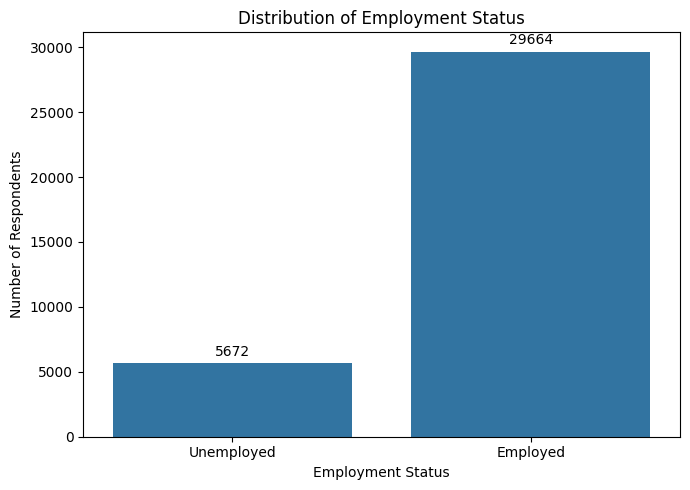

In [23]:
# EMPLOYMENT STATUS DISTRIBUTION
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=model_df,
    x="Employment_Status"
)

plt.title("Distribution of Employment Status")
plt.xlabel("Employment Status")
plt.ylabel("Number of Respondents")

plt.xticks(
    [0, 1],
    ["Unemployed", "Employed"]
)

# Add count labels above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3
    )

plt.tight_layout()
plt.show()

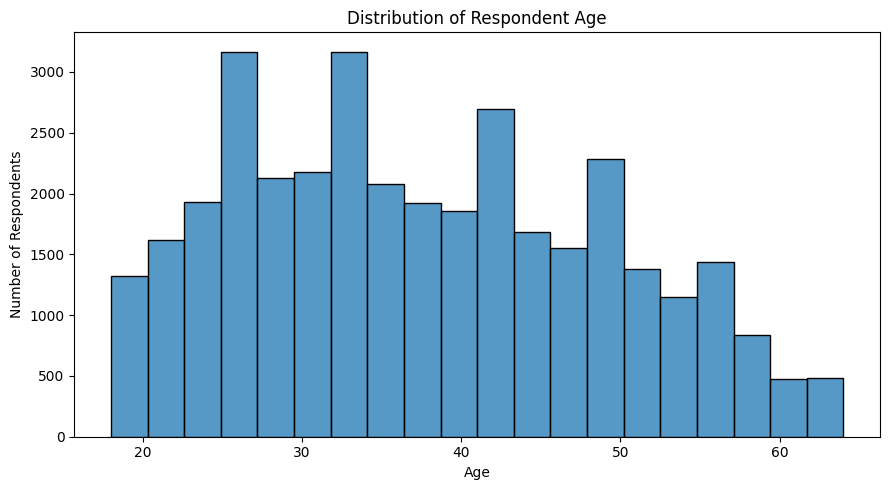

In [24]:
# AGE ANALYSIS

plt.figure(figsize=(9, 5))

ax = sns.histplot(
    data=model_df,
    x="Age_Final",
    bins=20
)

plt.title("Distribution of Respondent Age")
plt.xlabel("Age")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()

In [25]:
# Age statistics by employment status

age_by_employment = (
    model_df
    .groupby("Employment_Status")["Age_Final"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

age_by_employment.index = [
    "Unemployed",
    "Employed"
]

age_by_employment

,count,mean,median,std,min,max
Unemployed,5672,32.11,30.0,10.55,18.0,64.0
Employed,29664,38.75,38.0,11.22,18.0,64.0


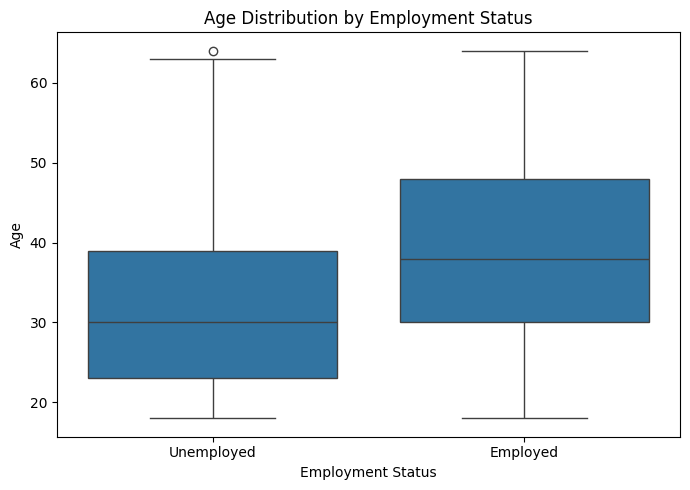

In [26]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=model_df,
    x="Employment_Status",
    y="Age_Final"
)

plt.title("Age Distribution by Employment Status")
plt.xlabel("Employment Status")
plt.ylabel("Age")

plt.xticks(
    [0, 1],
    ["Unemployed", "Employed"]
)

plt.tight_layout()
plt.show()

In [27]:
# EMPLOYMENT RATE BY AGE GROUP

model_df["Age_Group"] = pd.cut(
    model_df["Age_Final"],
    bins=[17, 24, 34, 44, 54, 64],
    labels=[
        "18–24",
        "25–34",
        "35–44",
        "45–54",
        "55–64"
    ]
)

age_employment = (
    model_df
    .groupby("Age_Group", observed=False)["Employment_Status"]
    .agg(
        Total="count",
        Employed="sum",
        Employment_Rate="mean"
    )
)

age_employment["Unemployed"] = (
    age_employment["Total"] -
    age_employment["Employed"]
)

age_employment["Employment_Rate"] = (
    age_employment["Employment_Rate"] * 100
).round(2)

age_employment

,Total,Employed,Employment_Rate,Unemployed
Age_Group,,,,
18–24,4870,3167,65.03,1703
25–34,10640,8713,81.89,1927
35–44,9351,8198,87.67,1153
45–54,7240,6542,90.36,698
55–64,3235,3044,94.10,191


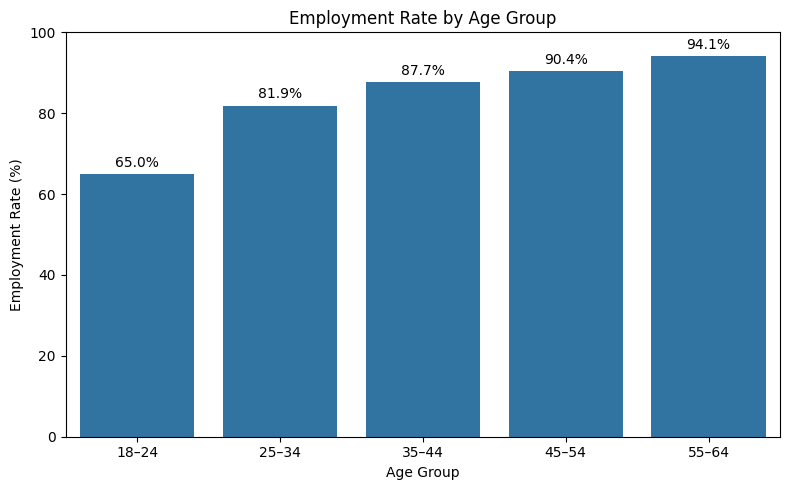

In [28]:
# Employment rate by age group

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=age_employment.reset_index(),
    x="Age_Group",
    y="Employment_Rate"
)

plt.title("Employment Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Employment Rate (%)")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [29]:
# EDUCATION ANALYSIS


education_employment = (
    model_df
    .groupby("Education_Final")["Employment_Status"]
    .agg(
        Total="count",
        Employed="sum",
        Employment_Rate="mean"
    )
)

education_employment["Unemployed"] = (
    education_employment["Total"] -
    education_employment["Employed"]
)

education_employment["Employment_Rate"] = (
    education_employment["Employment_Rate"] * 100
).round(2)

# Arrange education categories in a logical order
education_order = [
    "No schooling",
    "Primary",
    "Lower secondary",
    "Matric",
    "Post-school non-degree",
    "Bachelor's degree",
    "Postgraduate",
    "Unknown"
]

education_employment = education_employment.reindex(
    education_order
)

education_employment

,Total,Employed,Employment_Rate,Unemployed
Education_Final,,,,
No schooling,269,244,90.71,25
Primary,2890,2335,80.80,555
Lower secondary,12513,9621,76.89,2892
Matric,13462,11590,86.09,1872
Post-school non-degree,2619,2445,93.36,174
Bachelor's degree,1578,1532,97.08,46
Postgraduate,1505,1473,97.87,32
Unknown,500,424,84.80,76


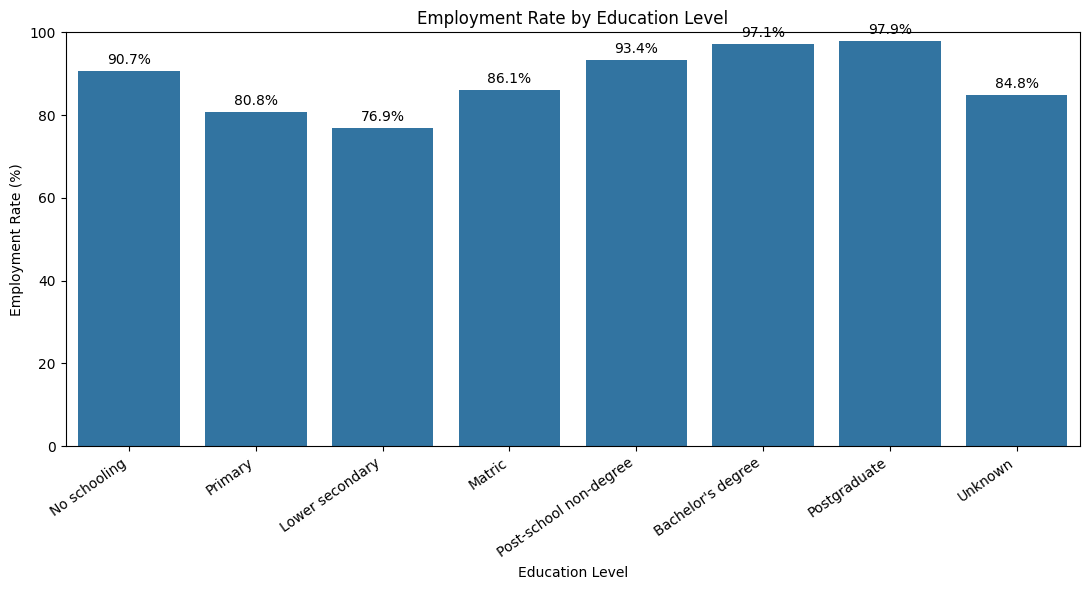

In [30]:
# Employment rate by education level

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=education_employment.reset_index(),
    x="Education_Final",
    y="Employment_Rate"
)

plt.title("Employment Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Employment Rate (%)")

# Add percentage labels above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.ylim(0, 100)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

In [31]:
# RACE ANALYSIS

race_employment = (
    model_df
    .groupby("Race_Final")["Employment_Status"]
    .agg(
        Total="count",
        Employed="sum",
        Employment_Rate="mean"
    )
)

race_employment["Unemployed"] = (
    race_employment["Total"] -
    race_employment["Employed"]
)

race_employment["Employment_Rate"] = (
    race_employment["Employment_Rate"] * 100
).round(2)

# Arrange categories
race_order = [
    "African/Black",
    "Coloured",
    "Indian/Asian",
    "White"
]

race_employment = race_employment.reindex(
    race_order
)

race_employment

,Total,Employed,Employment_Rate,Unemployed
Race_Final,,,,
African/Black,11391,8684,76.24,2707
Coloured,17699,14940,84.41,2759
Indian/Asian,299,276,92.31,23
White,5947,5764,96.92,183


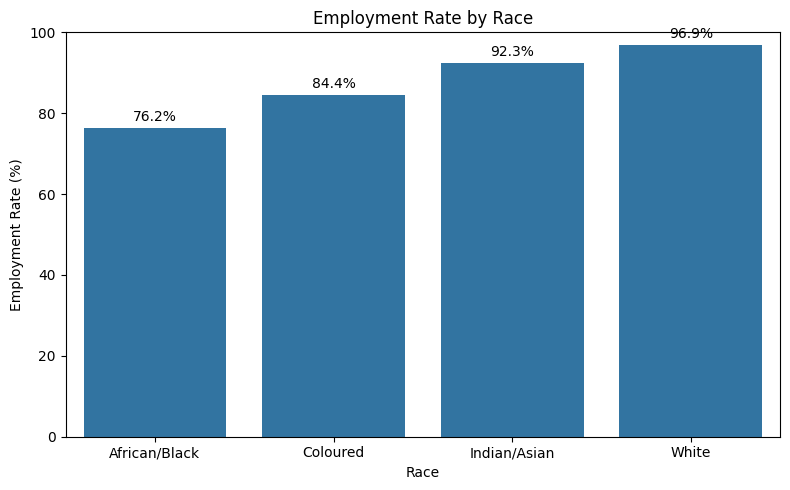

In [32]:
# Employment rate by race

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=race_employment.reset_index(),
    x="Race_Final",
    y="Employment_Rate"
)

plt.title("Employment Rate by Race")
plt.xlabel("Race")
plt.ylabel("Employment Rate (%)")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [33]:
# GENDER ANALYSIS

gender_employment = (
    model_df
    .groupby("Gender_Final")["Employment_Status"]
    .agg(
        Total="count",
        Employed="sum",
        Employment_Rate="mean"
    )
)

gender_employment["Unemployed"] = (
    gender_employment["Total"] -
    gender_employment["Employed"]
)

gender_employment["Employment_Rate"] = (
    gender_employment["Employment_Rate"] * 100
).round(2)

# Arrange categories
gender_order = [
    "Male",
    "Female"
]

gender_employment = gender_employment.reindex(
    gender_order
)

gender_employment

,Total,Employed,Employment_Rate,Unemployed
Gender_Final,,,,
Male,18378,15703,85.44,2675
Female,16958,13961,82.33,2997


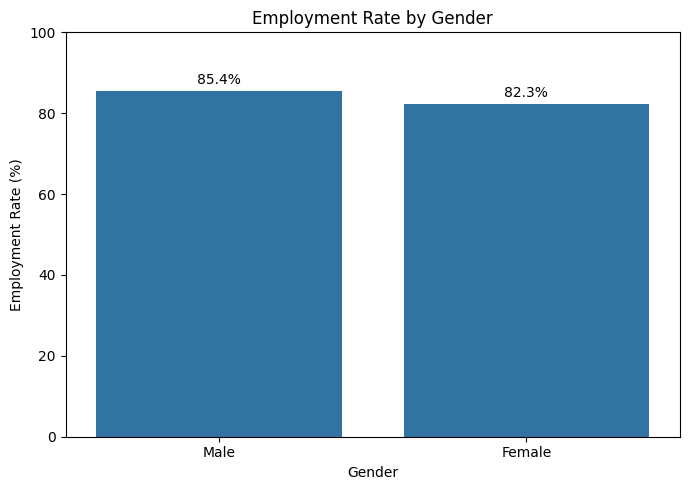

In [34]:
# Employment rate by gender

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=gender_employment.reset_index(),
    x="Gender_Final",
    y="Employment_Rate"
)

plt.title("Employment Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Employment Rate (%)")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [35]:
# GEOGRAPHIC LOCATION ANALYSIS

geography_employment = (
    model_df
    .groupby("Geography_Final")["Employment_Status"]
    .agg(
        Total="count",
        Employed="sum",
        Employment_Rate="mean"
    )
)

geography_employment["Unemployed"] = (
    geography_employment["Total"] -
    geography_employment["Employed"]
)

geography_employment["Employment_Rate"] = (
    geography_employment["Employment_Rate"] * 100
).round(2)

# Arrange categories
geography_order = [
    "Urban",
    "Rural"
]

geography_employment = geography_employment.reindex(
    geography_order
)

geography_employment

,Total,Employed,Employment_Rate,Unemployed
Geography_Final,,,,
Urban,33624,28027,83.35,5597
Rural,1712,1637,95.62,75


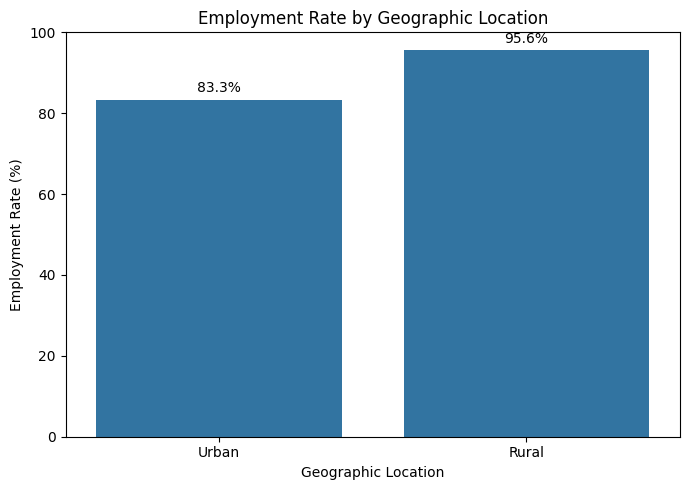

In [36]:
# Employment rate by geographic location

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=geography_employment.reset_index(),
    x="Geography_Final",
    y="Employment_Rate"
)

plt.title("Employment Rate by Geographic Location")
plt.xlabel("Geographic Location")
plt.ylabel("Employment Rate (%)")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [37]:
# EMPLOYMENT TRENDS BY SURVEY YEAR

year_employment = (
    model_df
    .groupby("Survey_Year")["Employment_Status"]
    .agg(
        Total="count",
        Employed="sum",
        Employment_Rate="mean"
    )
)

year_employment["Unemployed"] = (
    year_employment["Total"] -
    year_employment["Employed"]
)

year_employment["Employment_Rate"] = (
    year_employment["Employment_Rate"] * 100
).round(2)

year_employment

,Total,Employed,Employment_Rate,Unemployed
Survey_Year,,,,
2012,4813,4112,85.44,701
2013,4971,4353,87.57,618
2014,4954,4190,84.58,764
2015,3243,2780,85.72,463
2016,3256,2771,85.10,485
2017,3258,2745,84.25,513
2018,3194,2688,84.16,506
2019,2780,2255,81.12,525
2020,968,714,73.76,254


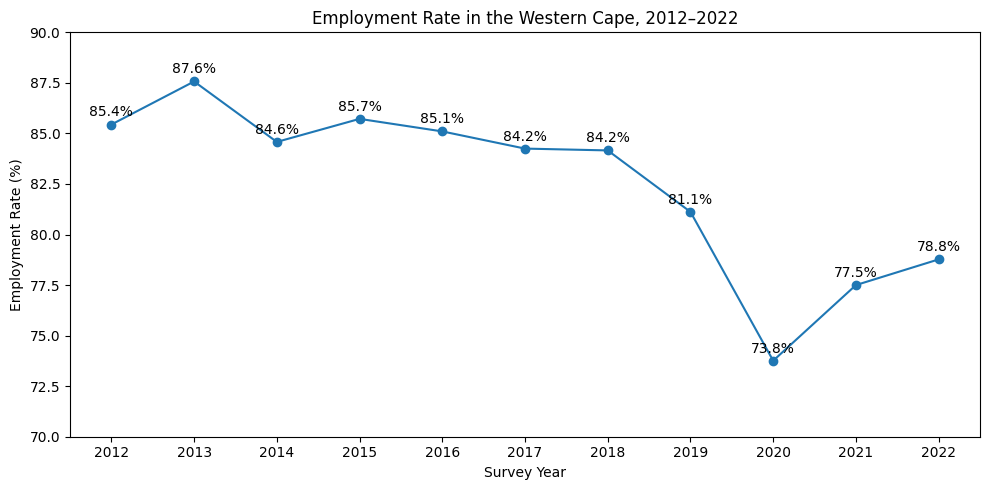

In [38]:
# Employment rate by survey year

plt.figure(figsize=(10, 5))

plt.plot(
    year_employment.index,
    year_employment["Employment_Rate"],
    marker="o"
)

# Add percentage labels
for year, rate in zip(
    year_employment.index,
    year_employment["Employment_Rate"]
):
    plt.text(
        year,
        rate + 0.4,
        f"{rate:.1f}%",
        ha="center"
    )

plt.title("Employment Rate in the Western Cape, 2012–2022")
plt.xlabel("Survey Year")
plt.ylabel("Employment Rate (%)")

plt.xticks(year_employment.index)

# Narrower axis to make changes over time visible
plt.ylim(70, 90)

plt.tight_layout()
plt.show()

In [39]:
# 5.9 STATISTICAL RELATIONSHIPS AND TESTS

from scipy.stats import pointbiserialr, chi2_contingency

# ============================================================
# 5.9.1 AGE AND EMPLOYMENT STATUS
# Point-Biserial Correlation
# ============================================================

correlation, p_value = pointbiserialr(
    model_df["Employment_Status"],
    model_df["Age_Final"]
)

print(f"Point-biserial correlation: {correlation:.3f}")
print(f"P-value: {p_value:.4g}")

Point-biserial correlation: 0.214
P-value: 0


In [40]:
# ============================================================
# CHI-SQUARE TEST FUNCTION
# ============================================================

def chi_square_test(data, variable, target="Employment_Status"):

    # Create contingency table
    contingency_table = pd.crosstab(
        data[variable],
        data[target]
    )

    # Chi-square test
    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    # Sample size
    n = contingency_table.to_numpy().sum()

    # Number of rows and columns
    r, k = contingency_table.shape

    # Cramér's V
    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, k - 1))
    )

    return {
        "Variable": variable,
        "Chi-square": round(chi2, 2),
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Cramer's V": round(cramers_v, 3)
    }

In [41]:
# Variables to test

categorical_variables = [
    "Education_Final",
    "Race_Final",
    "Gender_Final",
    "Geography_Final",
    "Survey_Year"
]

chi_square_results = []

for variable in categorical_variables:

    result = chi_square_test(
        model_df,
        variable
    )

    chi_square_results.append(result)

chi_square_results_df = pd.DataFrame(
    chi_square_results
)

chi_square_results_df

,Variable,Chi-square,Degrees of Freedom,P-value,Cramer's V
0,Education_Final,1130.29,7,8.361646e-240,0.179
1,Race_Final,1264.11,3,9.022307e-274,0.189
2,Gender_Final,63.39,1,1.699382e-15,0.042
3,Geography_Final,180.95,1,3.002753e-41,0.072
4,Survey_Year,250.70,10,3.874288e-48,0.084


# **6. Model Development and Training**

In [51]:
# 6.1 DEFINE FEATURES AND TARGET

# Predictor variables
X = model_df[
    [
        "Age_Final",
        "Education_Final",
        "Race_Final",
        "Gender_Final",
        "Geography_Final",
        "Survey_Year"
    ]
].copy()

# Target variable
y = model_df["Employment_Status"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

Features shape: (35336, 6)
Target shape: (35336,)

Target distribution:
Employment_Status
1    29664
0     5672
Name: count, dtype: int64

Target percentages:
Employment_Status
1    83.95
0    16.05
Name: proportion, dtype: float64


In [52]:
# 6.2 TRAIN-TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest target percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training set: (24735, 6)
Test set: (10601, 6)

Training target percentages:
Employment_Status
1    83.95
0    16.05
Name: proportion, dtype: float64

Test target percentages:
Employment_Status
1    83.94
0    16.06
Name: proportion, dtype: float64


In [54]:
# 6.3 PREPROCESSING PIPELINE

# Numerical variables
numeric_features = [
    "Age_Final"
]

# Categorical variables
categorical_features = [
    "Education_Final",
    "Race_Final",
    "Gender_Final",
    "Geography_Final",
    "Survey_Year"
]

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

## **Logistic Regression**

In [55]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            random_state=RANDOM_STATE,
            max_iter=1000
        ))
    ]
)

# Train model
logistic_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age_Final']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Education_Final',
                                                   'Race_Final', 'Gender_Final',
                                                   'Geography_Final',
                                                   'Survey_Year'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [56]:
# Generate predictions

y_pred_logistic = logistic_model.predict(X_test)

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

In [57]:
# ============================================================
# LOGISTIC REGRESSION EVALUATION
# ============================================================

logistic_accuracy = accuracy_score(
    y_test, y_pred_logistic
)

logistic_precision = precision_score(
    y_test, y_pred_logistic
)

logistic_recall = recall_score(
    y_test, y_pred_logistic
)

logistic_f1 = f1_score(
    y_test, y_pred_logistic
)

logistic_roc_auc = roc_auc_score(
    y_test, y_prob_logistic
)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall:    {logistic_recall:.4f}")
print(f"F1-score:  {logistic_f1:.4f}")
print(f"ROC-AUC:   {logistic_roc_auc:.4f}")

Logistic Regression Results
---------------------------
Accuracy:  0.8432
Precision: 0.8464
Recall:    0.9936
F1-score:  0.9141
ROC-AUC:   0.7600


In [58]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=[
            "Unemployed",
            "Employed"
        ]
    )
)


Classification Report:
              precision    recall  f1-score   support

  Unemployed       0.63      0.06      0.10      1702
    Employed       0.85      0.99      0.91      8899

    accuracy                           0.84     10601
   macro avg       0.74      0.53      0.51     10601
weighted avg       0.81      0.84      0.78     10601



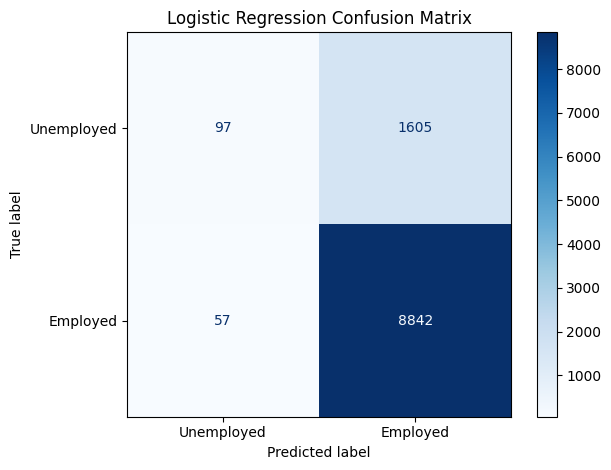

In [59]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    display_labels=[
        "Unemployed",
        "Employed"
    ],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

In [60]:
# ============================================================
# LOGISTIC REGRESSION - 5-FOLD CROSS-VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Logistic Regression 5-Fold Cross-Validation")
print("-------------------------------------------")

print(
    "Macro F1 Scores:",
    np.round(logistic_cv_scores, 4)
)

print(
    f"Mean Macro F1: "
    f"{logistic_cv_scores.mean():.4f}"
)

print(
    f"Standard Deviation: "
    f"{logistic_cv_scores.std():.4f}"
)

Logistic Regression 5-Fold Cross-Validation
-------------------------------------------
Macro F1 Scores: [0.5075 0.503  0.5065 0.5067 0.5   ]
Mean Macro F1: 0.5048
Standard Deviation: 0.0028


In [61]:
# ============================================================
# LOGISTIC REGRESSION HYPERPARAMETER TUNING
# ============================================================

logistic_param_grid = {
    "classifier__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

logistic_grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

# Use TRAINING DATA ONLY
logistic_grid_search.fit(
    X_train,
    y_train
)

print("Best C:")
print(
    logistic_grid_search.best_params_
)

print(
    f"\nBest CV Macro F1: "
    f"{logistic_grid_search.best_score_:.4f}"
)

Best C:
{'classifier__C': 100}

Best CV Macro F1: 0.5057


In [62]:
# ============================================================
# CLASS-WEIGHTED LOGISTIC REGRESSION
# ============================================================

balanced_logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier", LogisticRegression(
            C=100,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            max_iter=1000
        ))
    ]
)

balanced_logistic_cv_scores = cross_val_score(
    balanced_logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Class-Weighted Logistic Regression")
print("----------------------------------")

print(
    "Macro F1 Scores:",
    np.round(balanced_logistic_cv_scores, 4)
)

print(
    f"Mean Macro F1: "
    f"{balanced_logistic_cv_scores.mean():.4f}"
)

print(
    f"Standard Deviation: "
    f"{balanced_logistic_cv_scores.std():.4f}"
)

Class-Weighted Logistic Regression
----------------------------------
Macro F1 Scores: [0.5792 0.5733 0.574  0.5867 0.5869]
Mean Macro F1: 0.5800
Standard Deviation: 0.0059


In [63]:
# ============================================================
# FINAL LOGISTIC REGRESSION MODEL
# ============================================================

final_logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier", LogisticRegression(
            C=100,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            max_iter=1000
        ))
    ]
)

# Train the final model on the full training set
final_logistic_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age_Final']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Education_Final',
                                                   'Race_Final', 'Gender_Final',
                                                   'Geography_Final',
                                                   'Survey_Year'])])),
                ('classifier',
                 LogisticRegression(C=100, class_weight='balanced',
                                    max_iter=1000, random_state=42))])

## **Decision Tree**

In [64]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier", DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ))
    ]
)

decision_tree_model.fit(
    X_train,
    y_train
)

Baseline Decision Tree trained successfully.


In [65]:
# ============================================================
# DECISION TREE - TRAINING PERFORMANCE
# ============================================================

tree_train_pred = decision_tree_model.predict(
    X_train
)

tree_train_accuracy = accuracy_score(
    y_train,
    tree_train_pred
)

tree_train_macro_f1 = f1_score(
    y_train,
    tree_train_pred,
    average="macro"
)

print("Baseline Decision Tree - Training Performance")
print("---------------------------------------------")
print(f"Training Accuracy: {tree_train_accuracy:.4f}")
print(f"Training Macro F1: {tree_train_macro_f1:.4f}")

Baseline Decision Tree - Training Performance
---------------------------------------------
Training Accuracy: 0.8827
Training Macro F1: 0.7570


In [66]:
# ============================================================
# DECISION TREE - 5-FOLD CROSS-VALIDATION
# ============================================================

tree_cv_scores = cross_val_score(
    decision_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Decision Tree 5-Fold Cross-Validation")
print("-------------------------------------")

print(
    "Macro F1 Scores:",
    np.round(tree_cv_scores, 4)
)

print(
    f"Mean Macro F1: "
    f"{tree_cv_scores.mean():.4f}"
)

print(
    f"Standard Deviation: "
    f"{tree_cv_scores.std():.4f}"
)

Decision Tree 5-Fold Cross-Validation
-------------------------------------
Macro F1 Scores: [0.5912 0.5784 0.5828 0.5929 0.5836]
Mean Macro F1: 0.5858
Standard Deviation: 0.0054


In [67]:
# ============================================================
# DECISION TREE HYPERPARAMETER TUNING
# ============================================================

tree_param_grid = {
    "classifier__max_depth": [
        3, 5, 7, 10, 15, None
    ],

    "classifier__min_samples_split": [
        2, 5, 10, 20
    ],

    "classifier__min_samples_leaf": [
        1, 5, 10, 20
    ]
}

tree_grid_search = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=tree_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

# Tune using TRAINING DATA ONLY
tree_grid_search.fit(
    X_train,
    y_train
)

print("Best Decision Tree Parameters:")
print(tree_grid_search.best_params_)

print(
    f"\nBest CV Macro F1: "
    f"{tree_grid_search.best_score_:.4f}"
)

Best Decision Tree Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5}

Best CV Macro F1: 0.5890


In [68]:
# ============================================================
# DECISION TREE - CLASS WEIGHT TUNING
# ============================================================

tree_weight_param_grid = {
    "classifier__max_depth": [
        5, 10, 15, None
    ],

    "classifier__min_samples_split": [
        2, 5, 10, 20
    ],

    "classifier__min_samples_leaf": [
        1, 5, 10, 20
    ],

    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

tree_weight_grid_search = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=tree_weight_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

# Training data only
tree_weight_grid_search.fit(
    X_train,
    y_train
)

print("Best Decision Tree Parameters:")
print(tree_weight_grid_search.best_params_)

print(
    f"\nBest CV Macro F1: "
    f"{tree_weight_grid_search.best_score_:.4f}"
)

Best Decision Tree Parameters:
{'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5}

Best CV Macro F1: 0.5890


In [69]:
# ============================================================
# FINAL DECISION TREE MODEL
# ============================================================

final_decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier", DecisionTreeClassifier(
            max_depth=None,
            min_samples_split=5,
            min_samples_leaf=1,
            class_weight=None,
            random_state=RANDOM_STATE
        ))
    ]
)

# Train on the full training set
final_decision_tree_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age_Final']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Education_Final',
                                                   'Race_Final', 'Gender_Final',
                                                   'Geography_Final',
                                                   'Survey_Year'])])),
                ('classifier',
                 DecisionTreeClassifier(min_samples_split=5, random_state=42))])

## **Random Forest**

In [70]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(
    X_train,
    y_train
)

Baseline Random Forest trained successfully.


In [71]:
# ============================================================
# RANDOM FOREST - TRAINING PERFORMANCE
# ============================================================

rf_train_pred = random_forest_model.predict(
    X_train
)

rf_train_accuracy = accuracy_score(
    y_train,
    rf_train_pred
)

rf_train_macro_f1 = f1_score(
    y_train,
    rf_train_pred,
    average="macro"
)

print("Baseline Random Forest - Training Performance")
print("---------------------------------------------")
print(f"Training Accuracy: {rf_train_accuracy:.4f}")
print(f"Training Macro F1: {rf_train_macro_f1:.4f}")

Baseline Random Forest - Training Performance
---------------------------------------------
Training Accuracy: 0.8827
Training Macro F1: 0.7287


In [72]:
# ============================================================
# RANDOM FOREST - 5-FOLD CROSS-VALIDATION
# ============================================================

rf_cv_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Random Forest 5-Fold Cross-Validation")
print("-------------------------------------")

print(
    "Macro F1 Scores:",
    np.round(rf_cv_scores, 4)
)

print(
    f"Mean Macro F1: "
    f"{rf_cv_scores.mean():.4f}"
)

print(
    f"Standard Deviation: "
    f"{rf_cv_scores.std():.4f}"
)

Random Forest 5-Fold Cross-Validation
-------------------------------------
Macro F1 Scores: [0.5953 0.5695 0.5766 0.5939 0.5721]
Mean Macro F1: 0.5815
Standard Deviation: 0.0109


In [75]:
# ============================================================
# FASTER RANDOM FOREST HYPERPARAMETER TUNING
# ============================================================

rf_param_grid = {
    "classifier__n_estimators": [
        100, 200
    ],

    "classifier__max_depth": [
        10, 20, None
    ],

    "classifier__min_samples_leaf": [
        1, 5
    ],

    "classifier__max_features": [
        "sqrt"
    ]
}

rf_grid_search = GridSearchCV(
    estimator=random_forest_model,
    param_grid=rf_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

rf_grid_search.fit(
    X_train,
    y_train
)

print("Best Random Forest Parameters:")
print(rf_grid_search.best_params_)

print(
    f"\nBest CV Macro F1: "
    f"{rf_grid_search.best_score_:.4f}"
)

Best Random Forest Parameters:
{'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}

Best CV Macro F1: 0.5815


In [76]:
# ============================================================
# RANDOM FOREST - TEST CLASS WEIGHT
# ============================================================

rf_weight_param_grid = {
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

rf_weight_grid_search = GridSearchCV(
    estimator=rf_grid_search.best_estimator_,
    param_grid=rf_weight_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

rf_weight_grid_search.fit(
    X_train,
    y_train
)

print("Best Random Forest Parameters:")
print(rf_weight_grid_search.best_params_)

print(
    f"\nBest CV Macro F1: "
    f"{rf_weight_grid_search.best_score_:.4f}"
)

Best Random Forest Parameters:
{'classifier__class_weight': 'balanced'}

Best CV Macro F1: 0.5862


In [77]:
# ============================================================
# FINAL RANDOM FOREST MODEL
# ============================================================

final_random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            min_samples_leaf=1,
            max_features="sqrt",
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]
)

# Train on the full training set
final_random_forest_model.fit(
    X_train,
    y_train
)

print("Final Random Forest model trained successfully.")

Final Random Forest model trained successfully.


# **Model Evaluation**

In [78]:
# ============================================================
# 7.1 FINAL MODEL EVALUATION ON TEST DATA
# ============================================================

# Store final models in a dictionary
final_models = {
    "Logistic Regression": final_logistic_model,
    "Decision Tree": final_decision_tree_model,
    "Random Forest": final_random_forest_model
}

# Store results
model_results = []

for model_name, model in final_models.items():

    # Predictions
    y_pred = model.predict(X_test)

    # Probabilities for ROC-AUC
    y_prob = model.predict_proba(X_test)[:, 1]

    # Overall metrics
    accuracy = accuracy_score(y_test, y_pred)

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )

    # Employed = 1
    employed_precision = precision_score(
        y_test,
        y_pred,
        pos_label=1
    )

    employed_recall = recall_score(
        y_test,
        y_pred,
        pos_label=1
    )

    employed_f1 = f1_score(
        y_test,
        y_pred,
        pos_label=1
    )

    # Unemployed = 0
    unemployed_precision = precision_score(
        y_test,
        y_pred,
        pos_label=0
    )

    unemployed_recall = recall_score(
        y_test,
        y_pred,
        pos_label=0
    )

    unemployed_f1 = f1_score(
        y_test,
        y_pred,
        pos_label=0
    )

    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "ROC-AUC": roc_auc,
        "Employed Precision": employed_precision,
        "Employed Recall": employed_recall,
        "Employed F1": employed_f1,
        "Unemployed Precision": unemployed_precision,
        "Unemployed Recall": unemployed_recall,
        "Unemployed F1": unemployed_f1
    })


# Convert to DataFrame
results_df = pd.DataFrame(model_results)

# Round results
results_df = results_df.round(4)

results_df

,Model,Accuracy,Macro F1,ROC-AUC,Employed Precision,Employed Recall,Employed F1,Unemployed Precision,Unemployed Recall,Unemployed F1
0,Logistic Regression,0.6641,0.5866,0.7600,0.9242,0.6534,0.7656,0.2843,0.7197,0.4076
1,Decision Tree,0.7951,0.5861,0.6555,0.8642,0.8968,0.8802,0.3280,0.2632,0.2920
2,Random Forest,0.7331,0.5886,0.6785,0.8800,0.7898,0.8325,0.2845,0.4371,0.3447


In [79]:
# ============================================================
# 7.2 CLASSIFICATION REPORTS
# ============================================================

for model_name, model in final_models.items():

    y_pred = model.predict(X_test)

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Unemployed",
                "Employed"
            ]
        )
    )


Logistic Regression
              precision    recall  f1-score   support

  Unemployed       0.28      0.72      0.41      1702
    Employed       0.92      0.65      0.77      8899

    accuracy                           0.66     10601
   macro avg       0.60      0.69      0.59     10601
weighted avg       0.82      0.66      0.71     10601


Decision Tree
              precision    recall  f1-score   support

  Unemployed       0.33      0.26      0.29      1702
    Employed       0.86      0.90      0.88      8899

    accuracy                           0.80     10601
   macro avg       0.60      0.58      0.59     10601
weighted avg       0.78      0.80      0.79     10601


Random Forest
              precision    recall  f1-score   support

  Unemployed       0.28      0.44      0.34      1702
    Employed       0.88      0.79      0.83      8899

    accuracy                           0.73     10601
   macro avg       0.58      0.61      0.59     10601
weighted avg       0.78

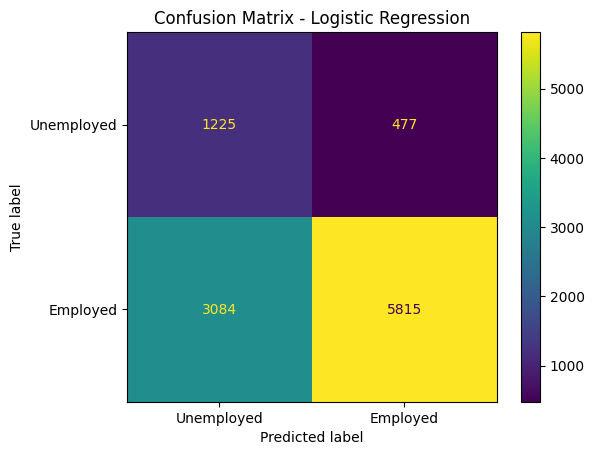

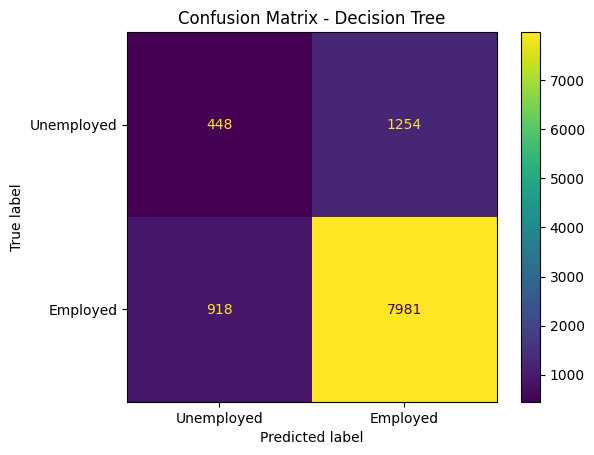

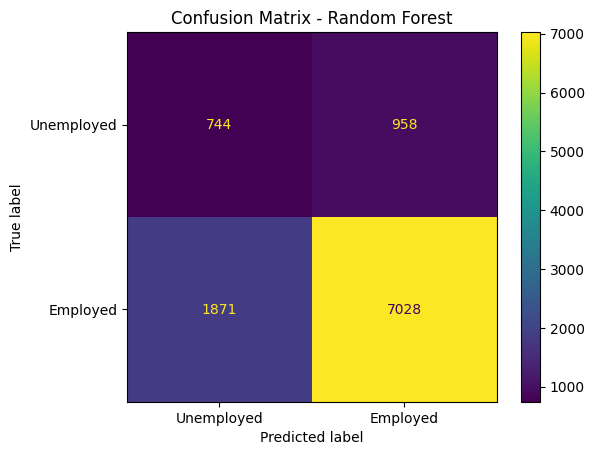

In [80]:
# ============================================================
# 7.3 CONFUSION MATRICES
# ============================================================

for model_name, model in final_models.items():

    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=[
            "Unemployed",
            "Employed"
        ]
    )

    plt.title(
        f"Confusion Matrix - {model_name}"
    )

    plt.show()

# **Feature Importance and Interpretation.**

In [81]:
# ============================================================
# 8.1 LOGISTIC REGRESSION COEFFICIENTS
# ============================================================

# Get the fitted preprocessor
logistic_preprocessor = final_logistic_model.named_steps[
    "preprocessor"
]

# Get transformed feature names
feature_names = logistic_preprocessor.get_feature_names_out()

# Get logistic regression coefficients
logistic_coefficients = final_logistic_model.named_steps[
    "classifier"
].coef_[0]

# Create DataFrame
logistic_coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": logistic_coefficients
})

# Calculate odds ratios
logistic_coef_df["Odds Ratio"] = np.exp(
    logistic_coef_df["Coefficient"]
)

# Sort from largest positive coefficient
logistic_coef_df = logistic_coef_df.sort_values(
    by="Coefficient",
    ascending=False
)

# Round for display
logistic_coef_df[
    ["Feature", "Coefficient", "Odds Ratio"]
].round(4)

,Feature,Coefficient,Odds Ratio
6,cat__Education_Final_Postgraduate,1.2871,3.6223
1,cat__Education_Final_Bachelor's degree,1.2205,3.3890
15,cat__Geography_Final_Rural,1.0389,2.8262
12,cat__Race_Final_White,0.8560,2.3538
0,num__Age_Final,0.6347,1.8864
18,cat__Survey_Year_2013,0.4742,1.6068
14,cat__Gender_Final_Male,0.4409,1.5542
5,cat__Education_Final_Post-school non-degree,0.4345,1.5441
11,cat__Race_Final_Indian/Asian,0.3776,1.4588
20,cat__Survey_Year_2015,0.3541,1.4248


In [82]:
# ============================================================
# 8.1 INTERPRETABLE LOGISTIC REGRESSION
# ============================================================

# Reference categories for categorical variables
reference_categories = [
    ["Lower secondary", "Bachelor's degree", "Matric",
     "No schooling", "Post-school non-degree",
     "Postgraduate", "Primary", "Unknown"],

    ["African/Black", "Coloured", "Indian/Asian", "White"],

    ["Female", "Male"],

    ["Urban", "Rural"],

    [2012, 2013, 2014, 2015, 2016, 2017,
     2018, 2019, 2020, 2021, 2022]
]


# Numerical preprocessing
interpret_numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


# Categorical preprocessing
interpret_categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                categories=reference_categories,
                drop="first",
                handle_unknown="ignore"
            )
        )
    ]
)


# Combine preprocessing
interpret_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            interpret_numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            interpret_categorical_transformer,
            categorical_features
        )
    ]
)


# Logistic Regression for interpretation
interpret_logistic_model = Pipeline(
    steps=[
        ("preprocessor", interpret_preprocessor),

        ("classifier", LogisticRegression(
            C=100,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            max_iter=1000
        ))
    ]
)


# Fit using TRAINING DATA
interpret_logistic_model.fit(
    X_train,
    y_train
)


# Get feature names
interpret_feature_names = (
    interpret_logistic_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)


# Get coefficients
interpret_coefficients = (
    interpret_logistic_model
    .named_steps["classifier"]
    .coef_[0]
)


# Create coefficient table
interpret_coef_df = pd.DataFrame({
    "Feature": interpret_feature_names,
    "Coefficient": interpret_coefficients
})


# Calculate odds ratios
interpret_coef_df["Odds Ratio"] = np.exp(
    interpret_coef_df["Coefficient"]
)


# Sort by coefficient
interpret_coef_df = interpret_coef_df.sort_values(
    "Coefficient",
    ascending=False
)


# Display
interpret_coef_df.round(4)

,Feature,Coefficient,Odds Ratio
5,cat__Education_Final_Postgraduate,1.9926,7.3346
1,cat__Education_Final_Bachelor's degree,1.9061,6.7268
12,cat__Geography_Final_Rural,1.5038,4.4987
10,cat__Race_Final_White,1.3984,4.0487
4,cat__Education_Final_Post-school non-degree,1.1068,3.0247
9,cat__Race_Final_Indian/Asian,0.9478,2.5799
2,cat__Education_Final_Matric,0.7044,2.0227
0,num__Age_Final,0.6357,1.8884
8,cat__Race_Final_Coloured,0.4114,1.5090
3,cat__Education_Final_No schooling,0.3459,1.4132


In [83]:
# ============================================================
# 8.2 RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

# Get fitted preprocessor
rf_preprocessor = final_random_forest_model.named_steps[
    "preprocessor"
]

# Get transformed feature names
rf_feature_names = (
    rf_preprocessor.get_feature_names_out()
)

# Get feature importance values
rf_importances = (
    final_random_forest_model
    .named_steps["classifier"]
    .feature_importances_
)

# Create DataFrame
rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

# Sort from most to least important
rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display results
rf_importance_df.round(4)

,Feature,Importance
0,num__Age_Final,0.6105
12,cat__Race_Final_White,0.0544
9,cat__Race_Final_African/Black,0.0320
2,cat__Education_Final_Lower secondary,0.0312
10,cat__Race_Final_Coloured,0.0160
3,cat__Education_Final_Matric,0.0146
6,cat__Education_Final_Postgraduate,0.0144
1,cat__Education_Final_Bachelor's degree,0.0139
14,cat__Gender_Final_Male,0.0139
13,cat__Gender_Final_Female,0.0137


In [84]:
# ============================================================
# GROUP RANDOM FOREST IMPORTANCE BY ORIGINAL VARIABLE
# ============================================================

def get_original_variable(feature):

    if "Age_Final" in feature:
        return "Age"

    elif "Education_Final" in feature:
        return "Education"

    elif "Race_Final" in feature:
        return "Race"

    elif "Gender_Final" in feature:
        return "Gender"

    elif "Geography_Final" in feature:
        return "Geography"

    elif "Survey_Year" in feature:
        return "Survey Year"

    else:
        return "Other"


rf_importance_df["Variable"] = (
    rf_importance_df["Feature"]
    .apply(get_original_variable)
)

grouped_rf_importance = (
    rf_importance_df
    .groupby("Variable")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

grouped_rf_importance["Importance"] = (
    grouped_rf_importance["Importance"].round(4)
)

grouped_rf_importance

,Variable,Importance
0,Age,0.6105
1,Survey Year,0.1296
2,Education,0.1062
3,Race,0.1047
4,Gender,0.0275
5,Geography,0.0215


In [85]:
# ============================================================
# 8.3 RANDOM FOREST PERMUTATION IMPORTANCE
# ============================================================

permutation_results = permutation_importance(
    final_random_forest_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Variable": X_test.columns,
    "Mean Importance": permutation_results.importances_mean,
    "Standard Deviation": permutation_results.importances_std
})

permutation_importance_df = (
    permutation_importance_df
    .sort_values(
        by="Mean Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

permutation_importance_df.round(4)

,Variable,Mean Importance,Standard Deviation
0,Age_Final,0.0441,0.0030
1,Education_Final,0.0196,0.0022
2,Race_Final,0.0156,0.0030
3,Geography_Final,0.0077,0.0016
4,Survey_Year,0.0006,0.0052
5,Gender_Final,-0.0026,0.0029
